# Coursera Week13

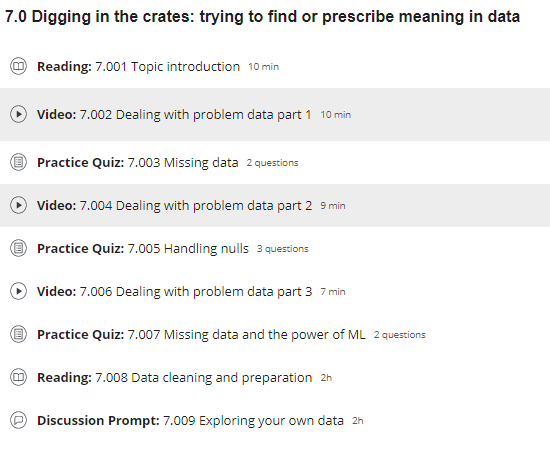

### 7.001 Topic introduction

You will remember me pointing to missing and problematic data earlier on in the course. It is now time to dig a little deeper conceptually and figure out how we can solve these problems.

This topic covers `a broad spectrum of concerns around missing, erroneous or problematic data`. We will also think about this in terms of our data processing pipelines and think about how we can `test our software` and `handle ` certain types of issues as and when they arise. Things get quite practical from here, so be prepared to dig deep into the literature to make sense of what is going on. We will gradually taper off support in order to encourage you to develop independent problem solving skills in Topic 8, so be prepared!

A lot of the stuff that we will see in `topics 7 and ` cover things where there might not be a clear cut answer. This is, unfortunately, `the job of a data programmer`. To find the unknown. To explore the contextual richness of data and make sense of it. We will start by reading about some of the techniques we can use.

Good luck and I am looking forward to seeing you on the discussion forums!

### 7.002 Dealing with problem data part 1


In [2]:

import pandas as pd
import numpy as np

myseries =pd.Series(['one', 'two', np.nan, 'four', None, "six"])
myseries

0     one
1     two
2     NaN
3    four
4    None
5     six
dtype: object

In [3]:
type(myseries[2])

float

In [4]:
type(myseries[4])

NoneType

In [5]:
myseries.values == None

array([False, False, False, False,  True, False])

In [6]:

import pandas as pd
import numpy as np

myseries =pd.Series(['one', 'two', None, 'four', None, "six"])
myseries

0     one
1     two
2    None
3    four
4    None
5     six
dtype: object

In [7]:
myseries.values == None

array([False, False,  True, False,  True, False])

In [8]:

import pandas as pd
import numpy as np

myseries =pd.Series([1, 2, None, 3, None, 6])
myseries

0    1.0
1    2.0
2    NaN
3    3.0
4    NaN
5    6.0
dtype: float64

In [9]:
myseries.isnull()

0    False
1    False
2     True
3    False
4     True
5    False
dtype: bool

In [10]:
myseries.values == None

array([False, False, False, False, False, False])

In [11]:

import pandas as pd
import numpy as np

myseries =pd.Series([1, 2, np.nan, 3, np.nan, 6])
myseries

0    1.0
1    2.0
2    NaN
3    3.0
4    NaN
5    6.0
dtype: float64

In [12]:
myseries.isnull()

0    False
1    False
2     True
3    False
4     True
5    False
dtype: bool

In [13]:

import pandas as pd
import numpy as np

myseries =pd.Series(['one', 'two', np.nan, 'four', np.nan, "six"])
myseries

0     one
1     two
2     NaN
3    four
4     NaN
5     six
dtype: object

In [14]:
myseries.isnull()

0    False
1    False
2     True
3    False
4     True
5    False
dtype: bool

In [15]:
myseries.values == None

array([False, False, False, False, False, False])

In [16]:

import pandas as pd
import numpy as np

myseries =pd.Series(['one', 'two', None, 'four', None, "six"])
myseries

0     one
1     two
2    None
3    four
4    None
5     six
dtype: object

In [17]:
myseries.isna()

0    False
1    False
2     True
3    False
4     True
5    False
dtype: bool

In [18]:
myseries.values == None

array([False, False,  True, False,  True, False])

In [19]:
from numpy import nan as NaN

In [20]:

import pandas as pd
import numpy as np

myseries =pd.Series(['one', 'two', np.nan, 'four', None, "six"])
myseries

0     one
1     two
2     NaN
3    four
4    None
5     six
dtype: object

In [21]:
myseries.isnull() # we don't want True value, because it's null

0    False
1    False
2     True
3    False
4     True
5    False
dtype: bool

In [22]:
myseries.isna() # we don't want True value, because it's null

0    False
1    False
2     True
3    False
4     True
5    False
dtype: bool

### Question: #### What's the different between isna and isnull? 6 minutes

In [23]:
myseries[myseries.notnull()]

0     one
1     two
3    four
5     six
dtype: object

In [24]:
myseries.dropna()

0     one
1     two
3    four
5     six
dtype: object

In [25]:
newseries = myseries.dropna()
newseries

0     one
1     two
3    four
5     six
dtype: object

In [26]:
from numpy import nan 
from pandas import DataFrame
data = DataFrame([[1., 6.5, 3.], [1., nan, nan], 
                  [nan, nan, nan], [ 6.5,nan, 3.]])
data

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
2,NaN,NaN,NaN
3,6.5,NaN,3.0


In [27]:
data.dropna()

,0,1,2
0,1.0,6.5,3.0


In [28]:
data.dropna(how="any")

,0,1,2
0,1.0,6.5,3.0


In [29]:
data.dropna(how="all")

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
3,6.5,NaN,3.0


In [30]:
data.dropna(thresh=1)

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
3,6.5,NaN,3.0


In [31]:
data.dropna(thresh=2)

,0,1,2
0,1.0,6.5,3.0
3,6.5,NaN,3.0


### Questions 6 minutes
Seeing from the result above ...
What is thresh?

In [63]:
data.dropna(axis=1,thresh=1)

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
2,NaN,NaN,NaN
3,6.5,NaN,3.0


In [64]:
data.dropna(axis=1,thresh=2)

,0,2
0,1.0,3.0
1,1.0,NaN
2,NaN,NaN
3,6.5,3.0


In [34]:
data.dropna(axis=1,thresh=3)

,0
0,1.0
1,1.0
2,NaN
3,6.5


### Questions:
Seeing from the result above ...
What is axis?

### Setting the seed to get the same number

In [35]:
from numpy import nan as NA
np.random.seed(116)
df = pd.DataFrame(np.random.rand(2,2,))
df

,0,1
0,0.375169,0.348707
1,0.928643,0.029138


In [36]:
df.iloc[1,1]=NA
df.dropna() # not assigned
df

,0,1
0,0.375169,0.348707
1,0.928643,NaN


In [37]:
np.random.seed(116)
df = pd.DataFrame(np.random.rand(5,5))
df

,0,1,2,3,4
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,0.992852
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,0.992520,0.755152
4,0.823879,0.603651,0.945014,0.989313,0.796384


In [38]:
df[df.iloc[:2]>=0.5]=np.nan
df

,0,1,2,3,4
0,0.375169,0.348707,NaN,0.029138,0.002492
1,NaN,0.041761,0.477994,0.361724,NaN
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,0.992520,0.755152
4,0.823879,0.603651,0.945014,0.989313,0.796384


###  7.003 Missing data (Quiz)

1. notnull() returns...
* `non-missing values`
* values that are more than zero

2. Why might we want to remove data if there is a corresponding value?
* `The value is outside a threshold`
* The value might be outside of the range of what Python can handle
* To make it easier to analyse
* The value could be incorrect and/or nonsense

###  7.004 Dealing with problem data part 2

In [39]:
import numpy as np
import pandas as pd
np.random.seed(116)
df = pd.DataFrame(np.random.rand(5,5))
df

,0,1,2,3,4
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,0.992852
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,0.992520,0.755152
4,0.823879,0.603651,0.945014,0.989313,0.796384


In [40]:
df[df.iloc[0:5]>0.95] = np.nan
df

,0,1,2,3,4
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,NaN
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,NaN,0.755152
4,0.823879,0.603651,0.945014,NaN,0.796384


In [41]:
df[3].isnull().sum()

2

In [42]:
df.isnull().sum()

0    0
1    0
2    0
3    2
4    1
dtype: int64

In [43]:
print(df[0].isnull().sum())

0


In [44]:
print(df[3].isnull().sum())

2


### What does it mean df[index]?

In [45]:
df.replace(np.nan, 0)                         # e.g., we don't like 99, then we give 0

,0,1,2,3,4
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,0.000000
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,0.000000,0.755152
4,0.823879,0.603651,0.945014,0.000000,0.796384


In [46]:
df.fillna(df.mean())                  

,0,1,2,3,4
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,0.394505
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,0.388918,0.755152
4,0.823879,0.603651,0.945014,0.388918,0.796384


In [47]:
df.fillna(df.mean(), inplace=True)   
df

,0,1,2,3,4
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,0.394505
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,0.388918,0.755152
4,0.823879,0.603651,0.945014,0.388918,0.796384


In [48]:
import numpy as np
import pandas as pd
np.random.seed(116)
df = pd.DataFrame(np.random.rand(5,5))
df.columns=['a','b','c','d','e']
df

,a,b,c,d,e
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,0.992852
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,0.992520,0.755152
4,0.823879,0.603651,0.945014,0.989313,0.796384


In [49]:
df[df.iloc[0:5]>0.95] = np.nan
df

,a,b,c,d,e
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,NaN
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,NaN,0.755152
4,0.823879,0.603651,0.945014,NaN,0.796384


In [50]:
df.fillna(df.mean())

,a,b,c,d,e
0,0.375169,0.348707,0.928643,0.029138,0.002492
1,0.783913,0.041761,0.477994,0.361724,0.394505
2,0.209143,0.905398,0.457036,0.775891,0.023992
3,0.406662,0.059720,0.297718,0.388918,0.755152
4,0.823879,0.603651,0.945014,0.388918,0.796384


### 7.005 Handling nulls


1. Why did we use isnull().sum in the lecture?
* `To look for how much data we were missing for a particular context`
* So that we could drop our missing data and optimise our workflow

2. What does the inplace parameter=true specification do?
* Creates a new correspondence mapping and updates the value in the new dataframe
* `Overwrites data in the existing dataframe`

3."Python and all of its libraries treat NA, NaN and 0 the same way"
* No 
*`It depends`
* Yes

Yes and No: [This is sometimes the case, but is context-specific for example when aggregating data we may want to include/not include values for the purpose of accuracy.]

### 7.006 Dealing with problem data part 3

#### strategy=mean, median

In [51]:
import numpy as np
import pandas as pd
np.random.seed(116)
df = pd.DataFrame(np.random.rand(5,5))
df[df.iloc[0:5]>0.95] = np.nan
values=df.values
values

array([[0.37516863, 0.34870741, 0.92864348, 0.02913782, 0.00249151],
       [0.7839126 , 0.04176065, 0.47799395, 0.36172369,        nan],
       [0.20914299, 0.90539812, 0.45703614, 0.77589144, 0.0239915 ],
       [0.40666239, 0.05972021, 0.29771805,        nan, 0.75515237],
       [0.82387944, 0.60365122, 0.94501383,        nan, 0.79638397]])

In [52]:
from numpy import isnan, nan
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=nan, strategy="mean")

imputer.fit_transform(values)


array([[0.37516863, 0.34870741, 0.92864348, 0.02913782, 0.00249151],
       [0.7839126 , 0.04176065, 0.47799395, 0.36172369, 0.39450484],
       [0.20914299, 0.90539812, 0.45703614, 0.77589144, 0.0239915 ],
       [0.40666239, 0.05972021, 0.29771805, 0.38891765, 0.75515237],
       [0.82387944, 0.60365122, 0.94501383, 0.38891765, 0.79638397]])

In [53]:
from numpy import isnan, nan
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=nan, strategy="median")

imputer.fit_transform(values)


array([[0.37516863, 0.34870741, 0.92864348, 0.02913782, 0.00249151],
       [0.7839126 , 0.04176065, 0.47799395, 0.36172369, 0.38957193],
       [0.20914299, 0.90539812, 0.45703614, 0.77589144, 0.0239915 ],
       [0.40666239, 0.05972021, 0.29771805, 0.36172369, 0.75515237],
       [0.82387944, 0.60365122, 0.94501383, 0.36172369, 0.79638397]])

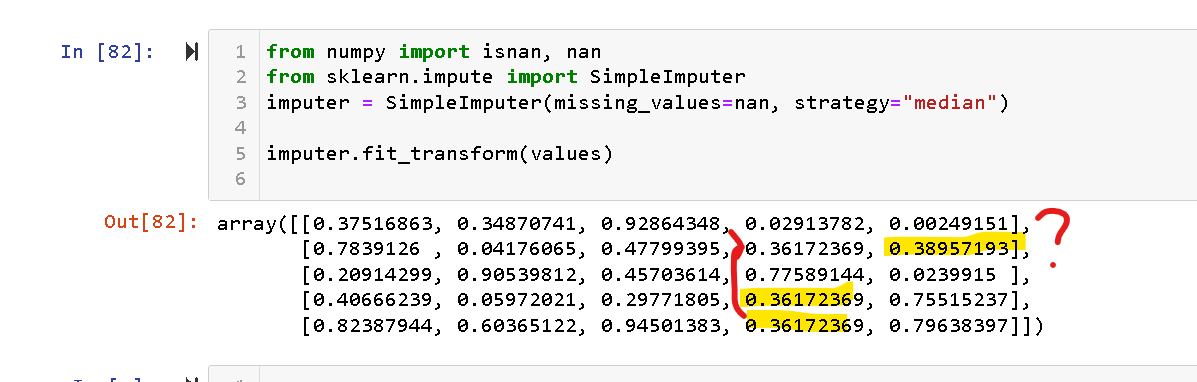
### Question:
Why are the value of the median different in the 4th columns and 5th columns, the 4th columns the number is taken from 0.36172369 and where the value 0.38957193 came from? 

In [54]:
np.nanmedian(values[:,4])

0.3895719335717266

In [55]:
values[3,4]

0.755152366557999

In [56]:
values[2,4]

0.023991500585454184

In [57]:
(values[3,4]+values[2,4])/2

0.3895719335717266

#### strategy=most_frequent

In [58]:
import numpy as np
import pandas as pd
np.random.seed(116)
df = pd.DataFrame(np.random.rand(5,5))
df[df.iloc[0:5]>0.95] = np.nan
values=df.values
values

array([[0.37516863, 0.34870741, 0.92864348, 0.02913782, 0.00249151],
       [0.7839126 , 0.04176065, 0.47799395, 0.36172369,        nan],
       [0.20914299, 0.90539812, 0.45703614, 0.77589144, 0.0239915 ],
       [0.40666239, 0.05972021, 0.29771805,        nan, 0.75515237],
       [0.82387944, 0.60365122, 0.94501383,        nan, 0.79638397]])

In [59]:
from numpy import isnan, nan
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=nan, strategy="most_frequent")

transformed_values = imputer.fit_transform(values)
transformed_values

array([[0.37516863, 0.34870741, 0.92864348, 0.02913782, 0.00249151],
       [0.7839126 , 0.04176065, 0.47799395, 0.36172369, 0.00249151],
       [0.20914299, 0.90539812, 0.45703614, 0.77589144, 0.0239915 ],
       [0.40666239, 0.05972021, 0.29771805, 0.02913782, 0.75515237],
       [0.82387944, 0.60365122, 0.94501383, 0.02913782, 0.79638397]])

### NON-USEFUL above.. why?

## Exercise

In [60]:
import pandas as pd
import numpy as np
students = [[85, 'M', 'verygood'],
           [95, 'F', 'excellent'],
           [75, None,'good'],
           [np.NaN, 'M', 'average'],
           [70, 'M', 'good'],
           [np.NaN, None, 'verygood'],
           [92, 'F', 'verygood'],
           [98, 'M', 'excellent']]
df = pd.DataFrame(students)
df.columns = ['marks', 'gender', 'result']


In [61]:
df

,marks,gender,result
0,85.0,M,verygood
1,95.0,F,excellent
2,75.0,None,good
3,NaN,M,average
4,70.0,M,good
5,NaN,None,verygood
6,92.0,F,verygood
7,98.0,M,excellent


In [66]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.NaN, strategy='mean') 
df['marks'] = imputer.fit_transform(df[['marks']]) 
print(df)

       marks gender     result
0  85.000000      M   verygood
1  95.000000      F  excellent
2  75.000000   None       good
3  85.833333      M    average
4  70.000000      M       good
5  85.833333   None   verygood
6  92.000000      F   verygood
7  98.000000      M  excellent


In [68]:
from numpy import isnan, nan
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=nan, strategy="most_frequent")

transformed_values = imputer.fit_transform(df[['marks']])
transformed_values

array([[85.        ],
       [95.        ],
       [75.        ],
       [85.83333333],
       [70.        ],
       [85.83333333],
       [92.        ],
       [98.        ]])

### 7.007 Missing data and the power of ML

1. Replacing missing values with most frequent representations might be problematic when...
* `We have a small dataset`
* The most frequent occurrence represents a high value

2. Machine learning algorithms can give us additional predictive and classification power.
* False
* `True`

### 7.008 Data cleaning and preparation

Please read the following reading, which will help you to familiarise yourself with some further  challenging elements:

McKinney, W. Python for data analysis: data wrangling with Pandas, NumPy, and IPython. (Sebastopol, CA: O'Reilly, 2017) 2nd edition, `Chapter 7` Data Cleaning and Preparation `pp.195–219`

### 7.009 Exploring your own data
Find a dataset of your own. Explore it and answer the following questions:

* Does it have any missing data?
* Are there any outliers or odd data that does not seem right to you?
* How would you go about solving this challenge?


Present your findings on the discussion forums. If you can, show off a few techniques that you have used to identify/solve some of the issues with your data and present any issues you still think need to be solved. Comment on at least one post from your peers.

Participation is optional


In [148]:
import pandas as pd
import numpy as np
from numpy import nan as NaN
students = [[19, 86, 'M', 'verygood'],
           [21, 96, 'F', 'excellent'],
           [32, 75, None,'good'],
           [np.NaN, np.NaN, 'M', 'good'],
           [np.NaN, 71, 'M', 'good'],
           [25, np.NaN, None, 'verygood'],
           [32, 92, 'F', 'verygood'],
           [np.NaN, 98, 'M', 'excellent']]
df = pd.DataFrame(students)
df.columns = ['age', 'marks', 'gender', 'result']


In [149]:
df

,age,marks,gender,result
0,19.0,86.0,M,verygood
1,21.0,96.0,F,excellent
2,32.0,75.0,None,good
3,NaN,NaN,M,good
4,NaN,71.0,M,good
5,25.0,NaN,None,verygood
6,32.0,92.0,F,verygood
7,NaN,98.0,M,excellent


In [150]:
df['age'].values.reshape(-1,1)

array([[19.],
       [21.],
       [32.],
       [nan],
       [nan],
       [25.],
       [32.],
       [nan]])

In [151]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.NaN, strategy='mean')

imputer.fit_transform(df['age'].values.reshape(-1,1))


array([[19. ],
       [21. ],
       [32. ],
       [25.8],
       [25.8],
       [25. ],
       [32. ],
       [25.8]])

In [152]:
df.age =imputer.fit_transform(df['age'].values.reshape(-1,1))


In [153]:
df

,age,marks,gender,result
0,19.0,86.0,M,verygood
1,21.0,96.0,F,excellent
2,32.0,75.0,None,good
3,25.8,NaN,M,good
4,25.8,71.0,M,good
5,25.0,NaN,None,verygood
6,32.0,92.0,F,verygood
7,25.8,98.0,M,excellent


### 

### Exercise `: Impute Marks using mean()

### Anything Wrong?

### Exercise 2: Impute Gender using most_frequent

### Exercise 3: Impute All the missing Values in Gender using 'F' (Code it as Female)

### 

In [154]:
np.set_printoptions(formatter={'float': '{: 0.3f}'.format})

In [155]:
np.set_printoptions(precision=2)

In [156]:
print(transformed_values)

[[0.38 0.35 0.93 0.03 0.  ]
 [0.78 0.04 0.48 0.36 0.  ]
 [0.21 0.91 0.46 0.78 0.02]
 [0.41 0.06 0.3  0.03 0.76]
 [0.82 0.6  0.95 0.03 0.8 ]]


In [157]:
np.set_printoptions(formatter={'float': lambda x: "{0:0.3f}".format(x)})

In [158]:
np.around(transformed_values, 0)

array([[0.000, 0.000, 1.000, 0.000, 0.000],
       [1.000, 0.000, 0.000, 0.000, 0.000],
       [0.000, 1.000, 0.000, 1.000, 0.000],
       [0.000, 0.000, 0.000, 0.000, 1.000],
       [1.000, 1.000, 1.000, 0.000, 1.000]])

In [159]:
print(np.round(transformed_values, 2))

[[0.380 0.350 0.930 0.030 0.000]
 [0.780 0.040 0.480 0.360 0.000]
 [0.210 0.910 0.460 0.780 0.020]
 [0.410 0.060 0.300 0.030 0.760]
 [0.820 0.600 0.950 0.030 0.800]]
